# 02 – Exploratory Data Analysis (medical datasets)
**Project 2 – Ensemble learning for disease prediction** (reference: Mahajan et al., 2024)

Goals of this notebook (they feed the *Dataset description* and *Experiments* sections of the report):
1. Check every dataset: size, class balance, missing values, duplicates, data types.
2. Make sure the **positive class = disease** is defined correctly (needed for precision / recall / F1).
3. Look for **data-leakage / too-easy-data signals**: duplicate rows shared by train and test, features that
   predict the target alone, baselines that score ~100 %.
4. Compare our counts with Table 2 of the article.

Run all cells (`Kernel > Restart & Run All`). UCI data downloads itself the first time (internet needed).
Kaggle files must be placed by hand in `data/raw/` (see README).

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from ensemble_disease.config import load_config, set_seed
from ensemble_disease.data import REGISTRY
from ensemble_disease import eda

cfg = load_config(); SEED = cfg["seed"]; set_seed(SEED)
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
eda.RESULTS.mkdir(exist_ok=True)
print("seed =", SEED)

seed = 42


## 1. Load the datasets
Each dataset is loaded as `(X, y)` with `y = 1` for the disease class.

In [2]:
data, errors = eda.load_all()
print(f"Loaded {len(data)}/{len(REGISTRY)} datasets:", list(data))
for k, v in errors.items():
    print(f"\n[NOT LOADED] {k}\n   {v}")
if errors:
    print("\n-> Fix the files above (see README, section Data) and re-run. The notebook continues with what is available.")

Loaded 7/9 datasets: ['D2_heart_cleveland', 'D5_liver_disorders', 'D6_ilpd', 'D8_early_diabetes', 'D11_debrecen', 'D12_ckd', 'D16_dermatology']

[NOT LOADED] D4_heart_failure
   FileNotFoundError: Place the Kaggle CSV at C:\Users\LENOVO\Downloads\ensemble_disease_step1\ensemble_disease\data\raw\D4_heart_failure.csv (see README).

[NOT LOADED] D10_diabetes_2019
   FileNotFoundError: Place the Kaggle CSV at C:\Users\LENOVO\Downloads\ensemble_disease_step1\ensemble_disease\data\raw\D10_diabetes_2019.csv (see README).

-> Fix the files above (see README, section Data) and re-run. The notebook continues with what is available.


## 2. Target definition (what is `y = 1`?)

In [3]:
pd.DataFrame({k: dict(positive_class_rule=v["note"]) for k, v in REGISTRY.items()}).T

,positive_class_rule
D2_heart_cleveland,"num 0 = healthy, 1..4 = disease -> disease =..."
D5_liver_disorders,"VERIFY: label = 'selector' (1: 145, 2: 200), '..."
D6_ilpd,"Selector 1 = liver patient (416), 2 = non-pati..."
D8_early_diabetes,class Positive / Negative
D11_debrecen,Class 1 = signs of diabetic retinopathy
D12_ckd,class ckd / notckd (raw file has stray tabs/sp...
D16_dermatology,VERIFY: 6 classes. Binarised as psoriasis (cla...
D4_heart_failure,Kaggle: heart_failure_clinical_records_dataset...
D10_diabetes_2019,VERIFY: Kaggle diabetes 2019 file; column name...


## 3. Summary table

In [4]:
summary = eda.summary_table(data)
summary.to_csv(eda.RESULTS / "eda_summary.csv")
display(summary)

,n,n_features,n_numeric,n_categorical,pos,neg,pos_pct,imbalance_ratio,missing_cells,missing_pct,rows_with_missing,duplicate_rows,duplicate_pct,constant_cols
dataset,,,,,,,,,,,,,,
D2_heart_cleveland,303,13,13,0,139,164,45.9,1.18,6,0.15,6,0,0.00,0
D5_liver_disorders,345,6,6,0,145,200,42.0,1.38,0,0.00,0,4,1.16,0
D6_ilpd,583,10,9,1,416,167,71.4,2.49,4,0.07,4,13,2.23,0
D8_early_diabetes,520,16,1,15,320,200,61.5,1.60,0,0.00,0,269,51.73,0
D11_debrecen,1151,19,19,0,611,540,53.1,1.13,0,0.00,0,5,0.43,0
D12_ckd,400,24,14,10,250,150,62.5,1.67,1012,10.54,242,0,0.00,0
D16_dermatology,366,34,34,0,112,254,30.6,2.27,8,0.06,8,0,0.00,0


**How to read it.** `imbalance_ratio` = majority / minority; above ~3 accuracy alone is misleading.
`duplicate_rows` are exact copies of another row (features only): a leakage risk when a random split puts copies on both sides.

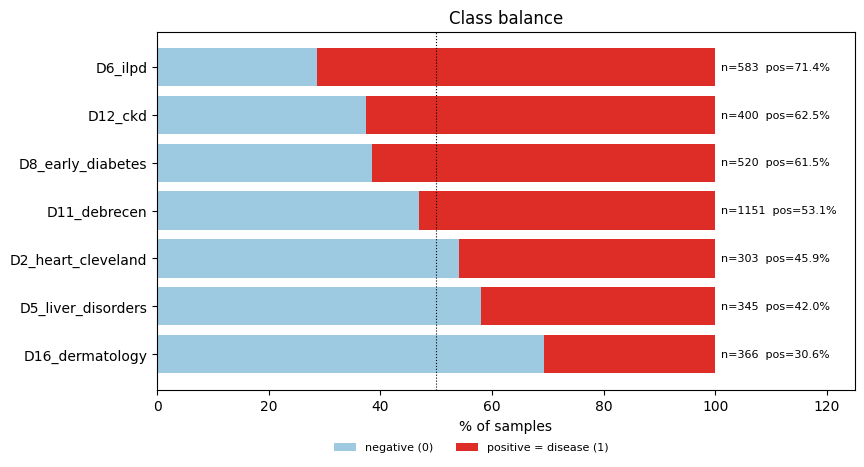

In [5]:
eda.plot_class_balance(summary); plt.show()

## 4. Missing values

,n,missing_cells,missing_pct,rows_with_missing
dataset,,,,
D2_heart_cleveland,303,6,0.15,6
D5_liver_disorders,345,0,0.00,0
D6_ilpd,583,4,0.07,4
D8_early_diabetes,520,0,0.00,0
D11_debrecen,1151,0,0.00,0
D12_ckd,400,1012,10.54,242
D16_dermatology,366,8,0.06,8


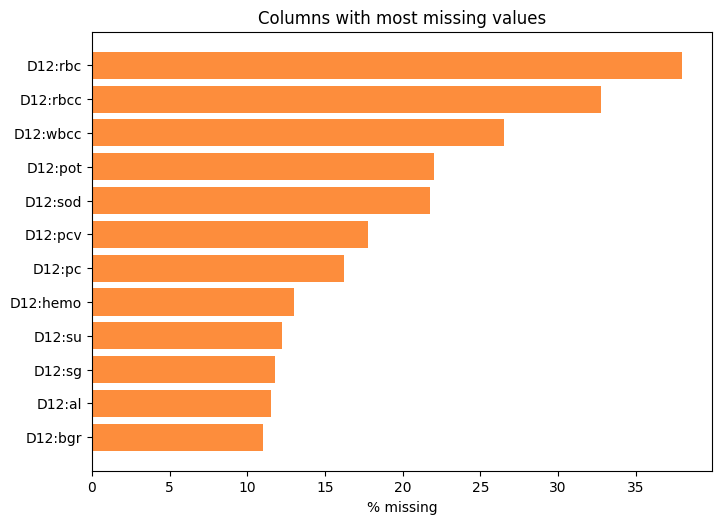

In [6]:
display(summary[["n", "missing_cells", "missing_pct", "rows_with_missing"]])
eda.plot_missing(data); plt.show()

## 5. Comparison with the article (Table 2)
Fill `ARTICLE` with the values from Table 2 of the paper (keys must match `n`, `n_features`, `pos`, `neg`),
then re-run the cell. Example: `"D2_heart_cleveland": dict(n=303, n_features=13)`.

In [7]:
ARTICLE = {
    # "D2_heart_cleveland": dict(n=..., n_features=...),
}
cmp_ = eda.compare_with_article(summary, ARTICLE)
display(cmp_ if len(cmp_) else "ARTICLE is empty: fill it from Table 2 of the paper.")

'ARTICLE is empty: fill it from Table 2 of the paper.'

## 6. Column types and text values
Look for typos, case/whitespace variants (`ckd` vs `ckd\t`), odd codes (`?`, `0` used as missing).

In [8]:
for name, (X, y) in data.items():
    print(f"\n===== {name}   shape={X.shape}")
    rep = eda.categorical_report(X)
    if len(rep):
        display(rep)
    else:
        print("   (all features numeric)")


===== D2_heart_cleveland   shape=(303, 13)
   (all features numeric)

===== D5_liver_disorders   shape=(345, 6)
   (all features numeric)

===== D6_ilpd   shape=(583, 10)


,column,n_unique,values
0,Gender,2,"{'Male': 441, 'Female': 142}"



===== D8_early_diabetes   shape=(520, 16)


,column,n_unique,values
0,gender,2,"{'Male': 328, 'Female': 192}"
1,polyuria,2,"{'No': 262, 'Yes': 258}"
2,polydipsia,2,"{'No': 287, 'Yes': 233}"
3,sudden_weight_loss,2,"{'No': 303, 'Yes': 217}"
4,weakness,2,"{'Yes': 305, 'No': 215}"
5,polyphagia,2,"{'No': 283, 'Yes': 237}"
6,genital_thrush,2,"{'No': 404, 'Yes': 116}"
7,visual_blurring,2,"{'No': 287, 'Yes': 233}"
8,itching,2,"{'No': 267, 'Yes': 253}"
9,irritability,2,"{'No': 394, 'Yes': 126}"



===== D11_debrecen   shape=(1151, 19)
   (all features numeric)

===== D12_ckd   shape=(400, 24)


,column,n_unique,values
0,rbc,2,"{'normal': 201, 'abnormal': 47}"
1,pc,2,"{'normal': 259, 'abnormal': 76}"
2,pcc,2,"{'notpresent': 354, 'present': 42}"
3,ba,2,"{'notpresent': 374, 'present': 22}"
4,htn,2,"{'no': 251, 'yes': 147}"
5,dm,2,"{'no': 261, 'yes': 137}"
6,cad,2,"{'no': 364, 'yes': 34}"
7,appet,2,"{'good': 317, 'poor': 82}"
8,pe,2,"{'no': 323, 'yes': 76}"
9,ane,2,"{'no': 339, 'yes': 60}"



===== D16_dermatology   shape=(366, 34)
   (all features numeric)


## 7. Leakage check A – exact duplicates between train and test

In [9]:
leak = pd.DataFrame({k: eda.duplicate_leakage(X, y, seed=SEED) for k, (X, y) in data.items()}).T
leak.to_csv(eda.RESULTS / "eda_duplicate_leakage.csv")
display(leak)

,test_rows_with_train_copy_pct,dup_groups,dup_groups_conflicting_labels
D2_heart_cleveland,0.00,0.0,0.0
D5_liver_disorders,1.71,4.0,0.0
D6_ilpd,3.56,13.0,0.0
D8_early_diabetes,68.88,107.0,0.0
D11_debrecen,0.68,5.0,0.0
D12_ckd,0.00,0.0,0.0
D16_dermatology,0.00,0.0,0.0


`test_rows_with_train_copy_pct` = % of test rows (random stratified 80/20 split, averaged over 50 splits) that have an
identical copy in the training set. Anything clearly above 0 means a memorising model (e.g. a deep tree, a stacking
with a tree meta-learner) gets part of the test set for free. `dup_groups_conflicting_labels` = identical inputs with
different labels (label noise: a ceiling on achievable accuracy).

## 8. Leakage check B – is a single feature almost the target?

In [10]:
auc_tables = {k: eda.single_feature_auc(X, y) for k, (X, y) in data.items()}
top = pd.DataFrame({k: dict(zip(["top1", "top2", "top3"],
        [f"{r.feature} ({r.strength})" for r in t.head(3).itertuples()])) for k, t in auc_tables.items()}).T
display(top)

,top1,top2,top3
D2_heart_cleveland,thal (0.764),cp (0.754),ca (0.749)
D5_liver_disorders,gammagt (0.628),sgot (0.584),sgpt (0.579)
D6_ilpd,Sgot (0.697),TB (0.693),Sgpt (0.686)
D8_early_diabetes,polyuria (0.842),polydipsia (0.832),gender (0.723)
D11_debrecen,ma1 (0.663),ma2 (0.648),ma3 (0.632)
D12_ckd,hemo (0.967),pcv (0.952),sc (0.922)
D16_dermatology,clubbing of the rete ridges (0.984),thinning of the suprapapillary epidermis (0.981),elongation of the rete ridges (0.916)


`strength = max(AUC, 1-AUC)` of the feature used alone. Above ~0.90 deserves a manual look (is it a consequence of the disease, e.g. a treatment or a diagnosis code?).

## 9. Sanity baselines (default models, 5-fold stratified CV)
*Not* the final protocol: imputation + one-hot encoding are inside the pipeline (fit on train folds only).

In [11]:
base = pd.DataFrame({k: eda.quick_baselines(X, y, seed=SEED) for k, (X, y) in data.items()}).T
base.to_csv(eda.RESULTS / "eda_baselines.csv")
display(base)

,majority_acc,majority_f1,majority_acc_std,tree_acc,tree_f1,tree_acc_std,forest_acc,forest_f1,forest_acc_std
D2_heart_cleveland,0.541,0.000,0.005,0.765,0.751,0.047,0.835,0.812,0.045
D5_liver_disorders,0.580,0.000,0.000,0.612,0.520,0.038,0.722,0.630,0.066
D6_ilpd,0.714,0.833,0.004,0.631,0.732,0.026,0.710,0.809,0.036
D8_early_diabetes,0.615,0.762,0.000,0.965,0.972,0.014,0.979,0.983,0.013
D11_debrecen,0.531,0.694,0.001,0.620,0.643,0.020,0.678,0.688,0.028
D12_ckd,0.625,0.769,0.000,0.975,0.980,0.018,0.992,0.994,0.006
D16_dermatology,0.694,0.000,0.006,0.995,0.991,0.007,1.000,1.000,0.000


Reading guide: if `forest_acc` is close to `majority_acc` the features carry little signal;
if `tree_acc` and `forest_acc` are ~1.00 the data is (nearly) trivially separable or leaks.
In both cases differences between ensemble methods will be tiny and statistically meaningless.

## 10. Correlations (numeric features)

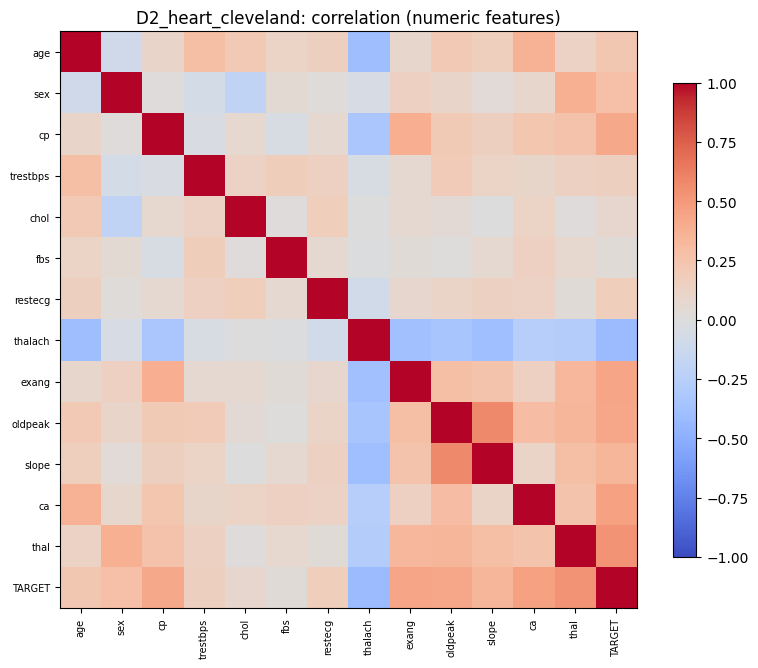

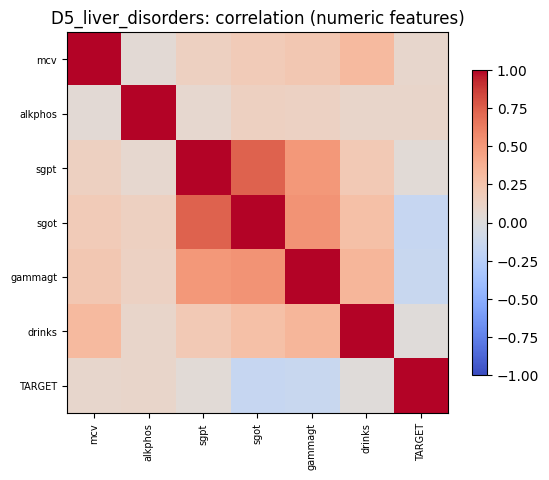

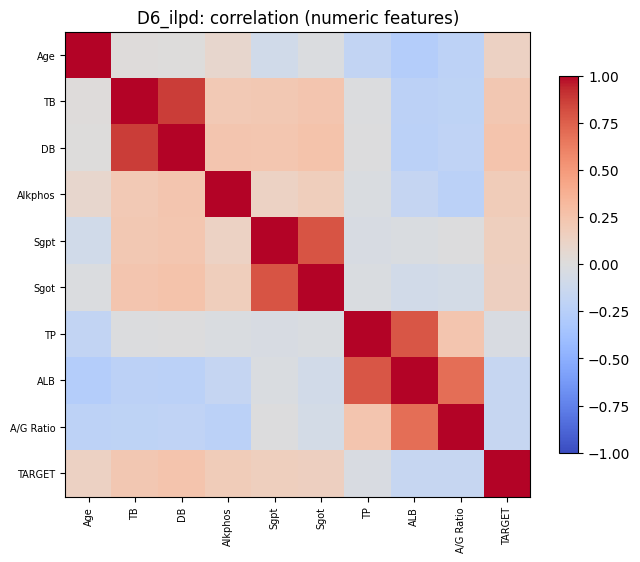

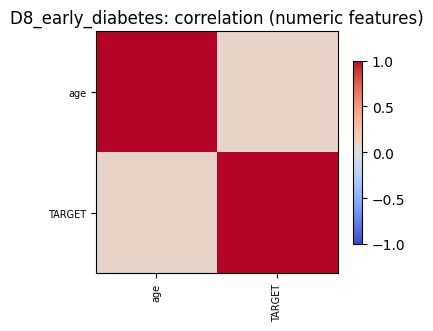

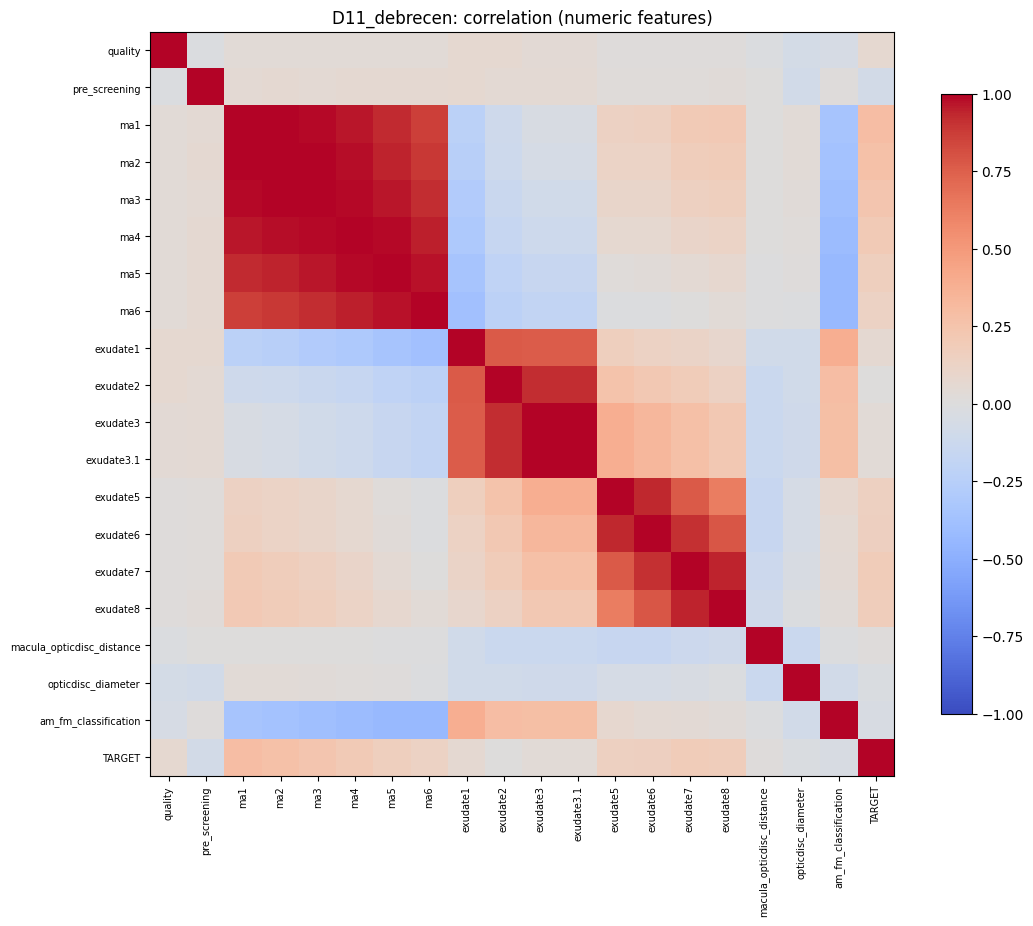

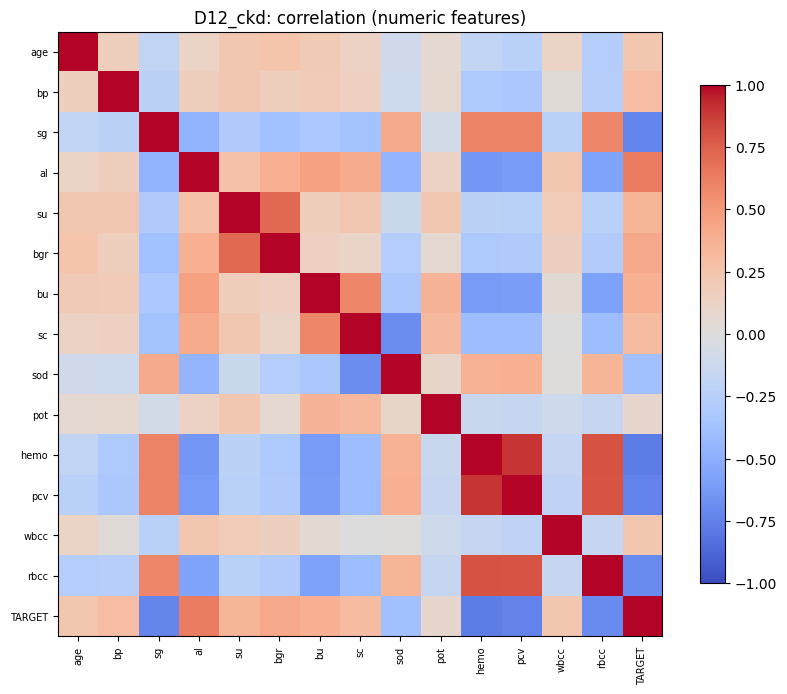

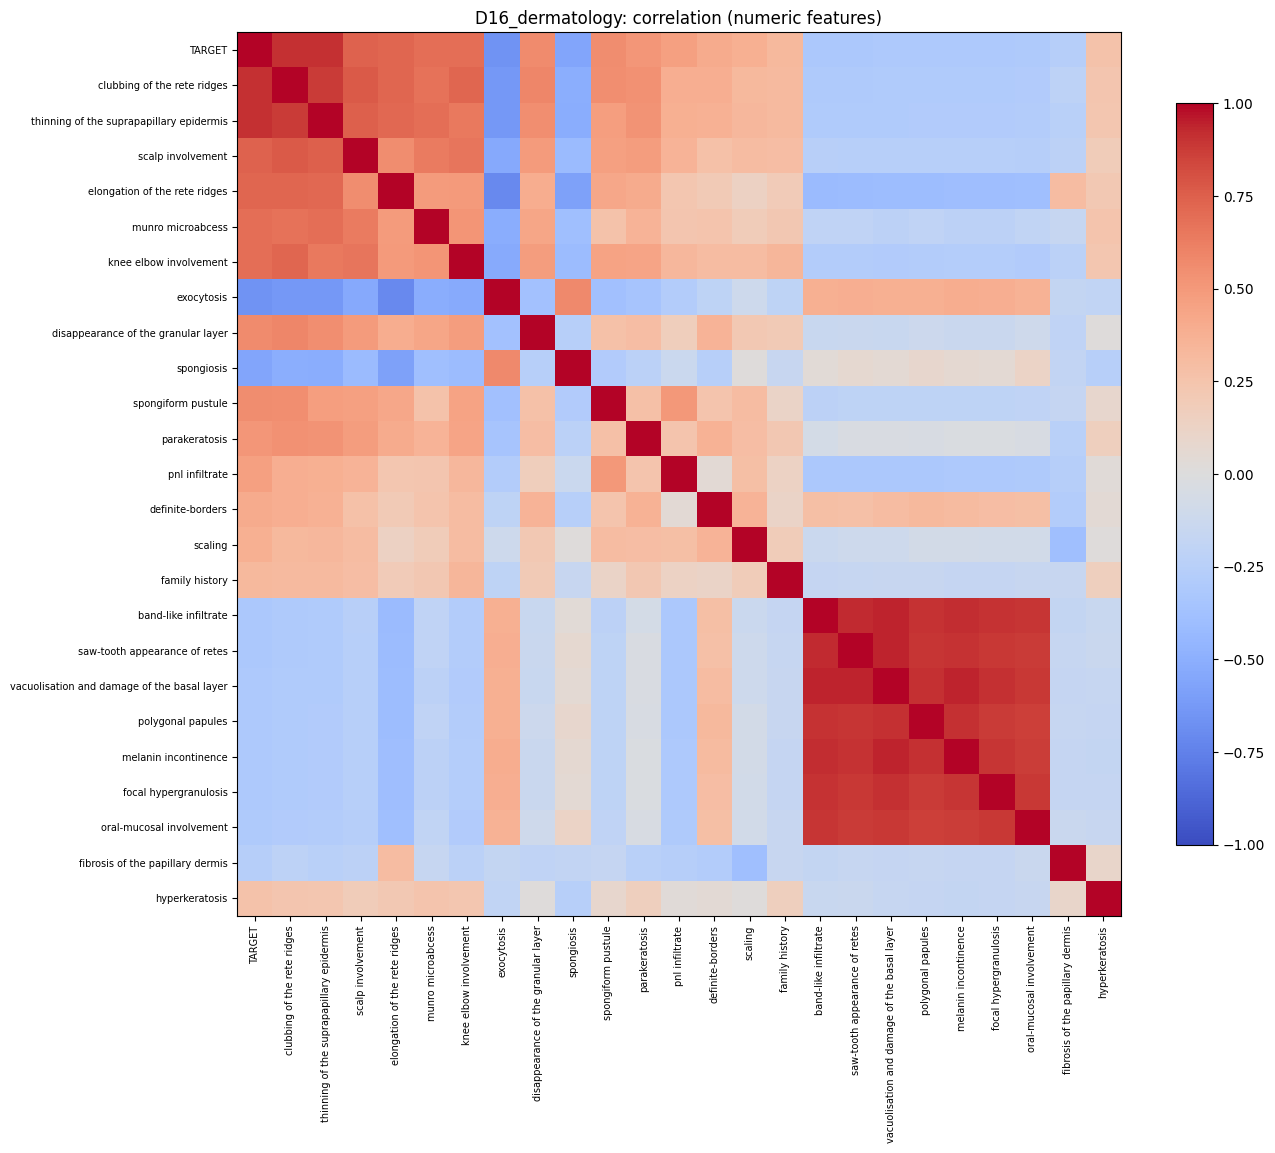

In [12]:
for name, (X, y) in data.items():
    eda.plot_corr(X, y, name); plt.show()

## 11. Automatic warnings

In [13]:
warn = []
for k in data:
    s = summary.astype(object).loc[k]   # keep ints as ints in the messages
    if s.imbalance_ratio >= 3: warn.append((k, f"imbalanced (ratio {s.imbalance_ratio}) -> use F1/AUPRC, stratified splits"))
    if s.missing_pct > 0:      warn.append((k, f"{s.missing_cells} missing cells -> imputation must be inside CV folds"))
    if s.duplicate_rows > 0:   warn.append((k, f"{s.duplicate_rows} duplicate rows ({s.duplicate_pct}%)"))
    if leak.loc[k, "test_rows_with_train_copy_pct"] >= 1: warn.append((k, f"{leak.loc[k,'test_rows_with_train_copy_pct']}% of test rows have a train copy"))
    if s.constant_cols > 0:    warn.append((k, f"{s.constant_cols} constant column(s)"))
    if s.n < 400:              warn.append((k, f"small (n={s.n}) -> high variance, use repeated CV"))
    if auc_tables[k].strength.iloc[0] >= 0.90: warn.append((k, f"feature '{auc_tables[k].feature.iloc[0]}' alone gives strength {auc_tables[k].strength.iloc[0]}"))
    if base.loc[k, "tree_acc"] >= 0.98: warn.append((k, f"a default tree already reaches {base.loc[k,'tree_acc']} accuracy (too easy / leakage?)"))
    if base.loc[k, "forest_acc"] - base.loc[k, "majority_acc"] < 0.05: warn.append((k, "forest barely beats the majority class"))
w = pd.DataFrame(warn, columns=["dataset", "warning"])
w.to_csv(eda.RESULTS / "eda_warnings.csv", index=False)
display(w if len(w) else "No warning.")

,dataset,warning
0,D2_heart_cleveland,6 missing cells -> imputation must be inside C...
1,D2_heart_cleveland,"small (n=303) -> high variance, use repeated CV"
2,D5_liver_disorders,4 duplicate rows (1.16%)
3,D5_liver_disorders,1.71% of test rows have a train copy
4,D5_liver_disorders,"small (n=345) -> high variance, use repeated CV"
5,D6_ilpd,4 missing cells -> imputation must be inside C...
6,D6_ilpd,13 duplicate rows (2.23%)
7,D6_ilpd,3.56% of test rows have a train copy
8,D6_ilpd,forest barely beats the majority class
9,D8_early_diabetes,269 duplicate rows (51.73%)
